<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/EX13-SUPERNOVA%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/1232702517.py:8: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


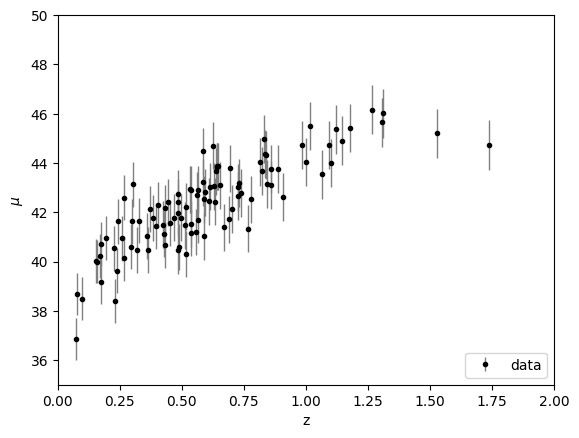

In [4]:
from astroML.datasets import generate_mu_z
from matplotlib import pyplot as plt

z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234) # YOU CANNOT CHANGE THIS

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50);

####  Tasks

- First, explore fitting this data with the tecniques we have seen.
- Start from linear regression and polynomial regression
- For the case of  polynomial regression, just fit many of them for now.
- Let's bet based on intuition! Which fit is the best?
- In what cases are you underfitting the data?
- In what cases are you overfitting the data?
- Now split the data into training and validation sets
- Implement a cross-validation procedure
- Pick the best!
- Does it agree with our bets?

#### OPTIONAL
- Repeat with Basis Function Regression and Kernel Regression
- Explore what happens when you change the number of datapoints and plot the resulting learning curves.

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/17302586.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")
/usr/local/lib/python3.13/dist-packages/astroML/linear_model/linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


(35.0, 50.0)

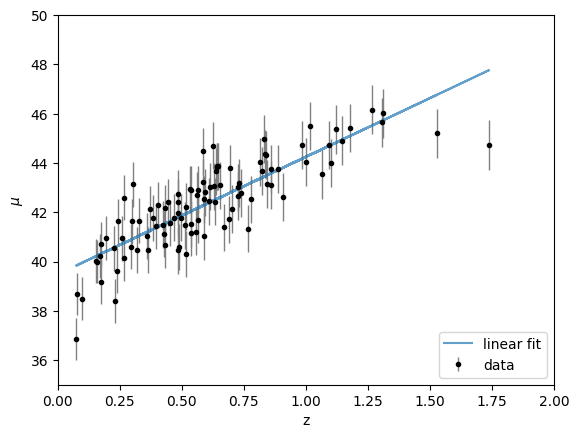

In [5]:
from astroML.linear_model import LinearRegression as LinReg

lr=LinReg()
z=z_sample.reshape(-1,1)
lr.fit(z, mu_sample, dmu)
mu_pred = lr.predict(z)

#plotting
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(z_sample,mu_pred,label='linear fit',alpha=0.7)
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)



POLINOMIAL FIT

<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/1407167135.py:16: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


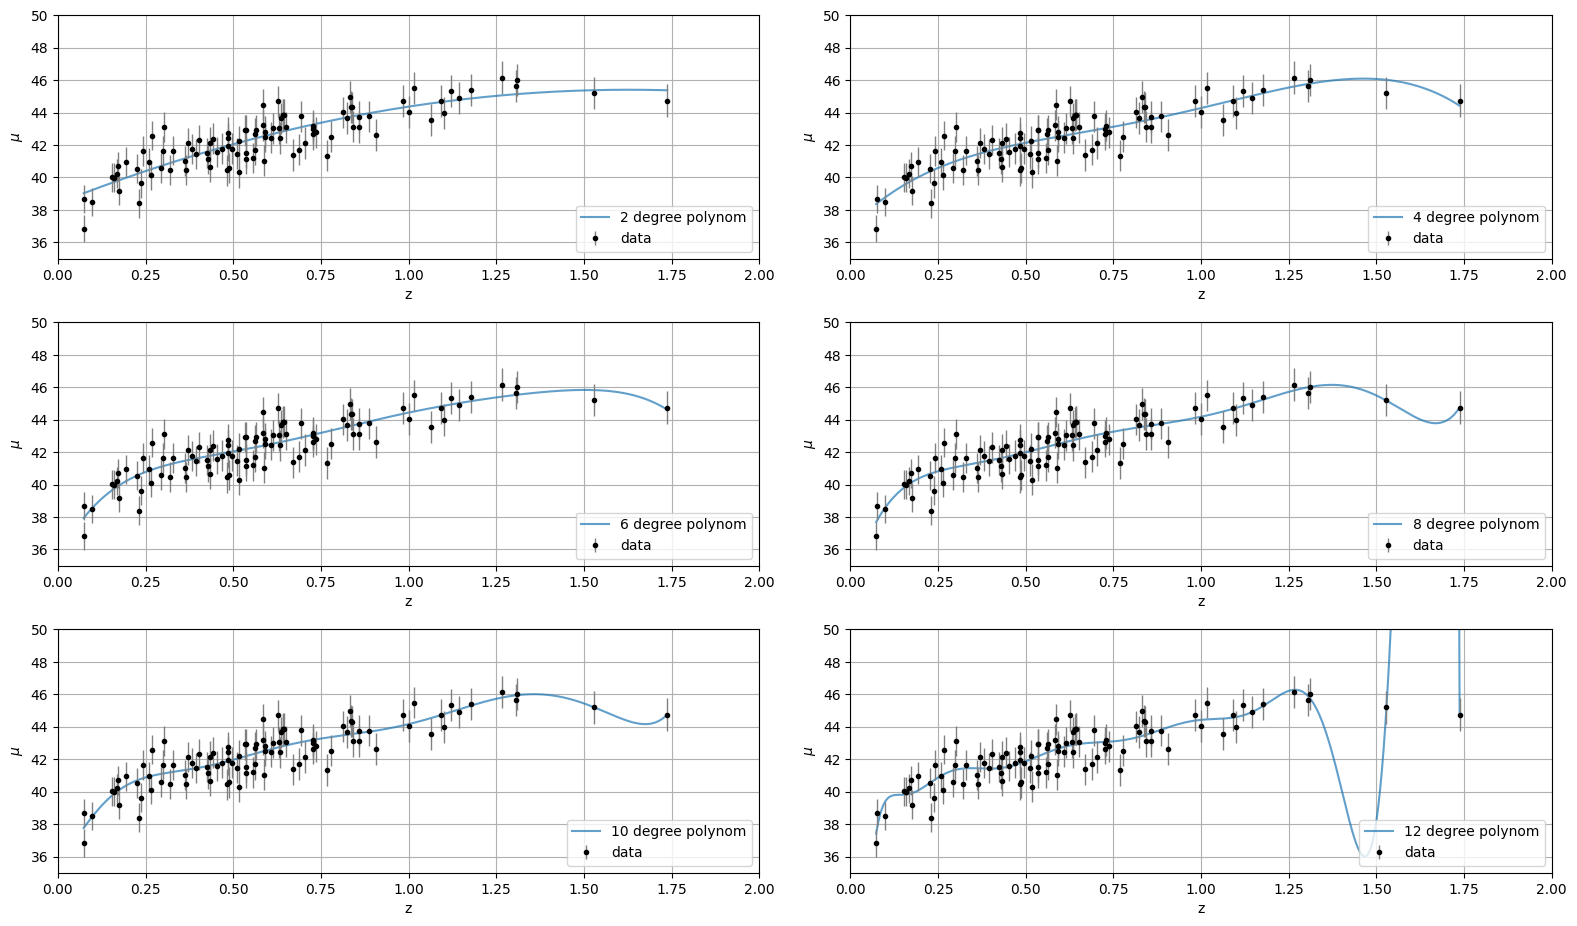

In [6]:
from astroML.linear_model import PolynomialRegression as PolReg
import numpy as np

plt.figure(figsize=(16, 12))
z_grid=np.linspace(min(z_sample),max(z_sample),1000)
for i in range (1,7):

  Pr=PolReg(degree=2*i)
  Pr.fit(z, mu_sample, dmu)
  mu_pred = Pr.predict(z_grid.reshape(-1,1))

  plt.subplot(4, 2, i)
  plt.plot(z_grid,mu_pred,label=f'{2*i} degree polynom',alpha=0.7)
  plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
  plt.xlabel("z")
  plt.ylabel("$\mu$")
  plt.legend(loc='lower right')
  plt.xlim(0,2)
  plt.grid()
  plt.ylim(35,50)

plt.tight_layout()
plt.show()


CROSS VALIDATING PARAMETERS

[np.float64(0.9605237480068448), np.float64(0.9069018338784716), np.float64(0.9151241474303164), np.float64(0.850678966552074), np.float64(0.8349028556326644), np.float64(0.8326759223399095), np.float64(0.7934396287253512), np.float64(0.7936217078097416), np.float64(0.8170369953010065), np.float64(0.8339067478504454), np.float64(1.1619539117895152)]


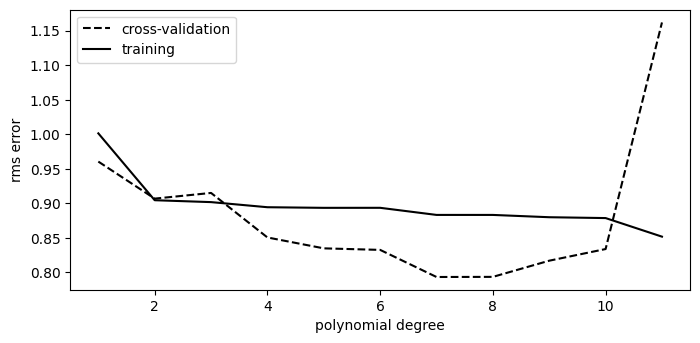

In [7]:
from sklearn.model_selection import train_test_split

#test train split
def train_test(test_size,x,y,dy,r_state):
  ydmu=np.array([y,dy]).T
  x_train, x_test, ydmu_train, ydmu_test = train_test_split(
    x, ydmu, test_size=test_size, random_state=r_state)
  return x_train,x_test,ydmu_train,ydmu_test

def error(x_train,x_test,ydmu_train,ydmu_test,degrees):
  training_err =[]
  crossval_err = []

  for degree in degrees:

    Pr=PolReg(degree=degree)
    Pr.fit(x_train, ydmu_train[:,0], ydmu_train[:,1])
    #fitting on train
    y_pred_train = Pr.predict(x_train)
    training_err.append( np.sqrt(np.sum((y_pred_train - ydmu_train[:,0]) ** 2)
                                 / len(ydmu_train[:,0])))

    #evaluate on test
    y_pred_test = Pr.predict(x_test)
    crossval_err.append( np.sqrt(np.sum((y_pred_test - ydmu_test[:,0]) ** 2)
                              / len(ydmu_test[:,0])))

  return crossval_err,training_err


def rms(test_size,x,y,dy,degrees,r_state):


  x_train,x_test,ydmu_train,ydmu_test=train_test(test_size,x,y,dy,r_state)
  crossval_err,training_err= error(x_train,x_test,ydmu_train,ydmu_test,degrees)
  return  x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err



degrees = np.arange(1,12)

x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err= rms(0.33,z,mu_sample,dmu,degrees,0)
print(crossval_err)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(211)
ax.plot(degrees, crossval_err, '--k', label='cross-validation')
ax.plot(degrees, training_err, '-k', label='training')

ax.set_xlabel('polynomial degree')
ax.set_ylabel('rms error')
ax.legend(loc=2)




RMS error seems to suggest an 8 degree polynomial

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/1880062708.py:9: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


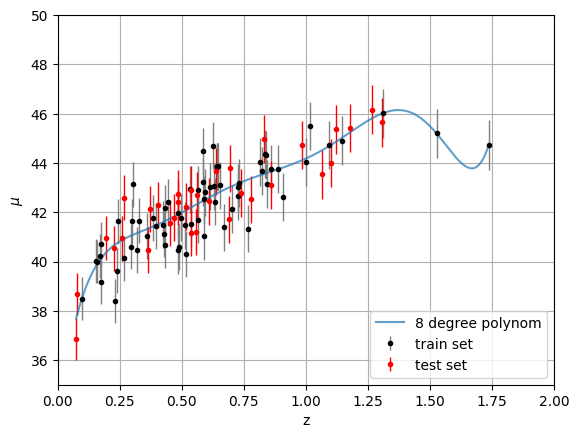

In [8]:
Pr=PolReg(degree=8)
Pr.fit(z, mu_sample, dmu)
mu_pred = Pr.predict(z_grid.reshape(-1,1))
#plotting
plt.errorbar(x_train, ydmu_train[:,0],ydmu_train[:,1] ,fmt='.k', ecolor='gray', lw=1,label='train set')
plt.errorbar(x_test,ydmu_test[:,0],ydmu_test[:,1],fmt='.r', ecolor='red', lw=1,label='test set')
plt.plot(z_grid,mu_pred,label=f'8 degree polynom',alpha=0.7)
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.grid()


* **GridSearchCV**

`GridSearchCV` automates *model selection* by exhaustively searching over a specified grid of hyperparameters (`param_grid`) using **$K$-fold cross-validation**

1. **Grid & $K$-fold splitting:** For every hyperparameter combination in `param_grid`, the *training set* is partitioned into $K$ subsets (*folds*, specified by `cv=K`)
2. **Training & Validation:** The model is trained $K$ times on $K-1$ *folds* and evaluated each time on the held-out *validation fold*, computing the average score across all $K$ runs.
3. **Selection & Final Refit:** It identifies the combination that yields the best cross-validation score (`best_params_`) and automatically retrains the optimal model on the **entire *training set*** , ready for a final evaluation on the independent *test set*.


In [9]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(PolReg(), {'degree': degrees},scoring='neg_root_mean_squared_error') #Polinomial Regression does not have score implemented
grid.fit(z,mu_sample)
degree = grid.best_params_['degree']
print(degree)

2


* **Changing the train-test set dimention**

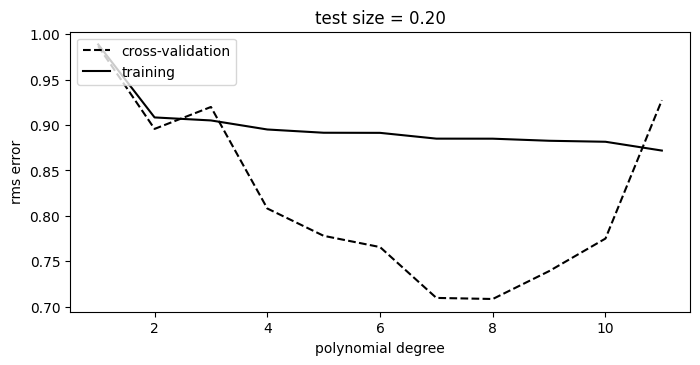

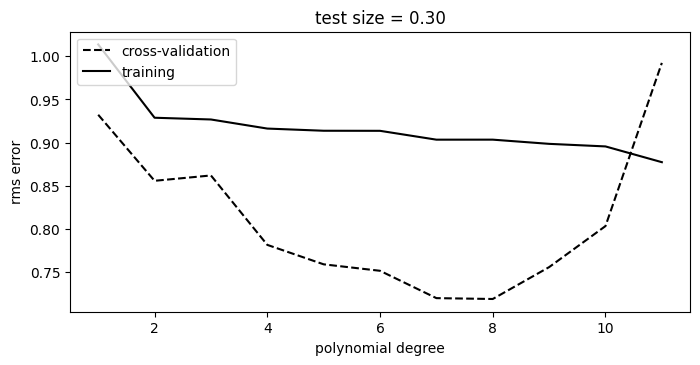

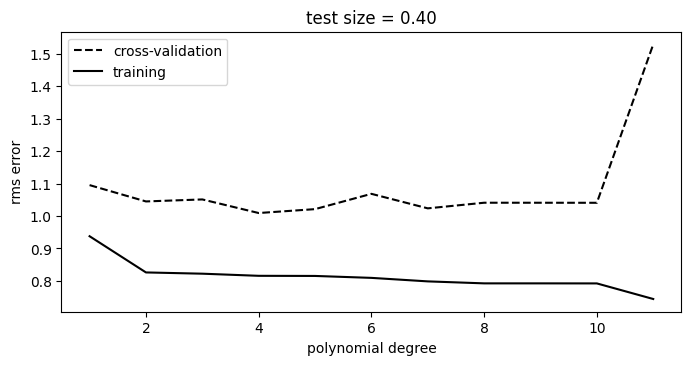

In [10]:
for test_size in np.linspace(0.2,0.4,3):
  fig = plt.figure(figsize=(8, 8))
  x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err= rms(test_size,z,mu_sample,dmu,degrees,0)
  ax = fig.add_subplot(211)
  ax.plot(degrees, crossval_err, '--k', label='cross-validation')
  ax.plot(degrees, training_err, '-k', label='training')
  ax.set_xlabel('polynomial degree')
  ax.set_ylabel('rms error')
  ax.set_title(f'test size = {test_size:.2f}')
  ax.legend(loc=2)


* **Data driven outliers exclusion**

<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/2995808283.py:16: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


(94, 3)


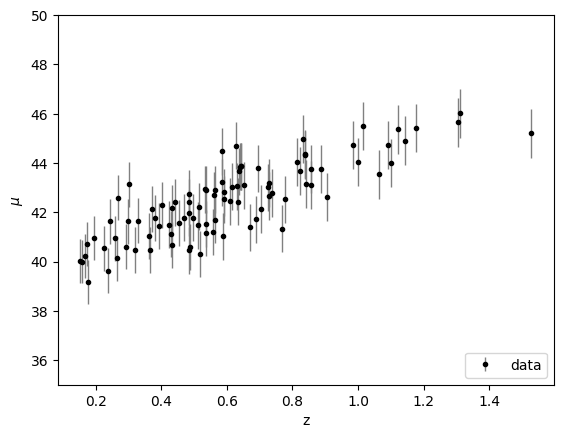

In [11]:
from sklearn.cluster import DBSCAN as db

def DB(data):
  dbscan = db() #The maximum distance between two samples for one to be considered as in the neighborhood of the other.
  labels = dbscan.fit_predict(data)
  inliers = data[labels != -1]
  return inliers

data=np.array([z_sample, mu_sample, dmu]).T
inliers= DB(data)



plt.errorbar(inliers[:,0], inliers[:,1], inliers[:,2], fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.ylim(35,50)
print(inliers.shape)

#BDSCAN here only used for computing the inliers but is a clustering alghoritm itself!

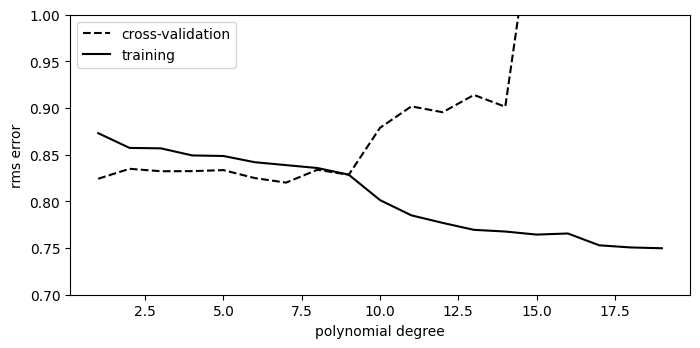

In [12]:
degreee=np.arange(1,20,1)
x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err= rms(0.33,inliers[:,0].reshape(-1,1),inliers[:,1],inliers[:,2],degreee,0)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(211)
ax.plot(degreee, crossval_err, '--k', label='cross-validation')
ax.plot(degreee, training_err, '-k', label='training')
plt.ylim(0.7,1)
ax.set_xlabel('polynomial degree')
ax.set_ylabel('rms error')
ax.legend(loc=2)



<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/1243145628.py:10: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


(35.0, 50.0)

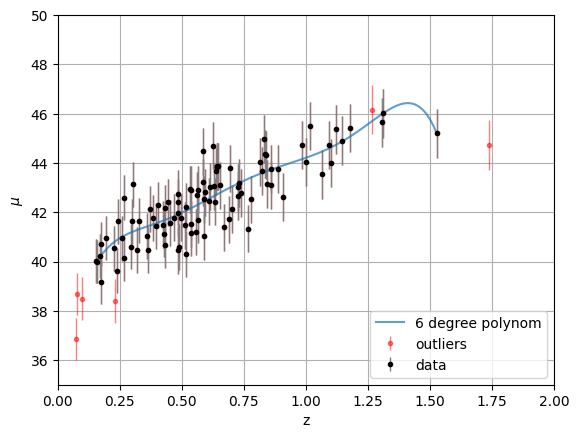

In [13]:
Pr=PolReg(degree=np.argmin(crossval_err))
z_grid=np.linspace(np.min(inliers[:,0]),np.max(inliers[:,0]),len(inliers[:,0]))
Pr.fit(inliers[:,0].reshape(-1,1),inliers[:,1],inliers[:,2])
mu_pred = Pr.predict(z_grid.reshape(-1,1))

plt.errorbar(z_sample, mu_sample, dmu, fmt='.r', ecolor='red', lw=1,label='outliers',alpha=0.5)
plt.errorbar(inliers[:,0],inliers[:,1],inliers[:,2], fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(z_grid,mu_pred,label=f'{np.argmin(crossval_err)} degree polynom',alpha=0.7)
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.grid()
plt.ylim(35,50)

* **REMOVING OUTLIERS NOT DATA DRIVEN**





5


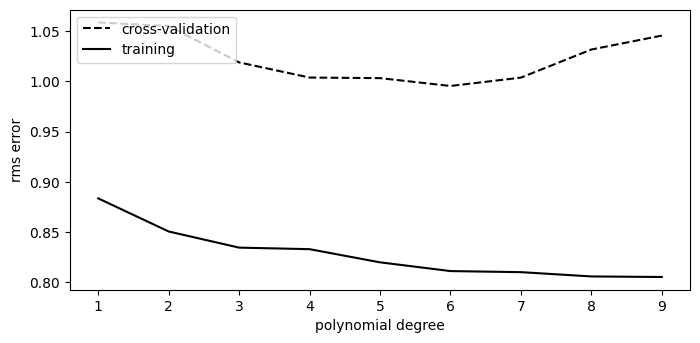

In [14]:
z_in= z_sample[z_sample<1.5]
mu_in=mu_sample[z_sample<1.5]
dmu_in=dmu[z_sample<1.5]


degreee=np.arange(1,10,1)
x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err= rms(0.33,z_in.reshape(-1,1),mu_in,dmu_in,degreee,0)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(211)
ax.plot(degreee, crossval_err, '--k', label='cross-validation')
ax.plot(degreee, training_err, '-k', label='training')

ax.set_xlabel('polynomial degree')
ax.set_ylabel('rms error')
ax.legend(loc=2)

print(np.argmin(crossval_err))







<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1499/254426363.py:11: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


(35.0, 50.0)

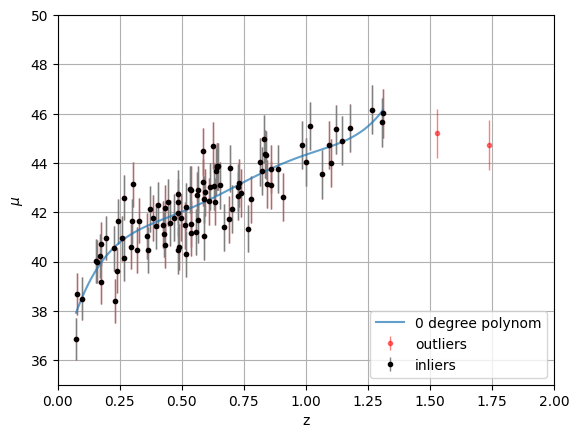

In [18]:
Pr=PolReg(degree=5)
z_grid=np.linspace(np.min(z_in),np.max(z_in),len(z_in))
Pr.fit(z_in.reshape(-1,1),mu_in,dmu_in)
mu_pred = Pr.predict(z_grid.reshape(-1,1))

plt.errorbar(z_sample, mu_sample, dmu, fmt='.r', ecolor='red', lw=1,label='outliers',alpha=0.5)
plt.errorbar(z_in, mu_in, dmu_in, fmt='.k', ecolor='gray', lw=1,label='inliers')
plt.plot(z_grid,mu_pred,label=f'{np.argmin(crossval_err)} degree polynom',alpha=0.7)

plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.grid()
plt.ylim(35,50)

*  ITERATING TEST VALIDATION SPLIT AND TAKING THE MEAN





5


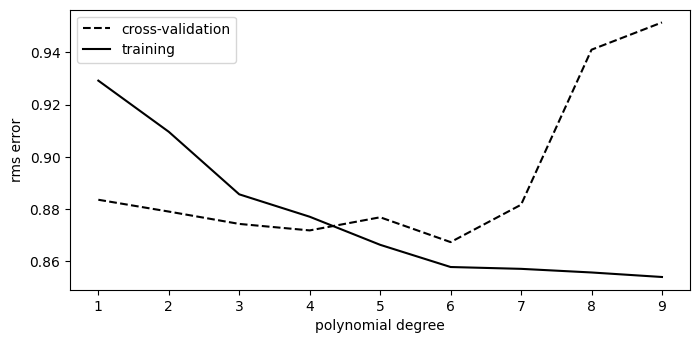

In [21]:
degrees=np.arange(1,10,1)
random_states=[0,67,42,123,71]
cross_tot=np.zeros(len(degrees))
train_tot=np.zeros(len(degrees))
for rand_states in random_states:
  x_train, x_test, ydmu_train, ydmu_test,crossval_err,training_err= rms(0.1,z_in.reshape(-1,1),mu_in,dmu_in,degrees,rand_states)

  cross_val=np.array(crossval_err)
  train_val=np.array(training_err)

  cross_tot=cross_tot+cross_val
  train_tot=train_tot+train_val

cross_tot=cross_tot/5
train_tot=train_tot/5


fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(211)
ax.plot(degrees, cross_tot, '--k', label='cross-validation')
ax.plot(degrees, train_tot, '-k', label='training')

ax.set_xlabel('polynomial degree')
ax.set_ylabel('rms error')
ax.legend(loc=2)


print(np.argmin(cross_tot))

* **K-Fold Cross-Validation is strictly preferable** for model selection (hyperparameter tuning of the polynomial degree), especially in low-statistics regimes ($N = 100$), as it maximizes data efficiency and provides a stable, lower-variance estimate of generalization performance.
